In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(
    r"C:\Users\61005\OneDrive\Documents\Pradeep Pandey\Nexvia Technology  Intership\Project 1"
)

DATA_DIR = PROJECT_DIR / "data"
IMAGE_DIR = DATA_DIR / "sample" / "images"
CSV_PATH = DATA_DIR / "sample" / "sample_labels.csv"

print("Image folder:", IMAGE_DIR.exists())
print("Labels file:", CSV_PATH.exists())
print("Number of images:", len(list(IMAGE_DIR.glob("*.png"))))

Image folder: True
Labels file: True
Number of images: 5606


In [5]:
import pandas as pd

df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (5606, 11)

Columns:
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImageWidth', 'OriginalImageHeight', 'OriginalImagePixelSpacing_x', 'OriginalImagePixelSpacing_y']

First 5 rows:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImageWidth,OriginalImageHeight,OriginalImagePixelSpacing_x,OriginalImagePixelSpacing_y
0,00000013_005.png,Emphysema|Infiltration|Pleural_Thickening|Pneu...,5,13,060Y,M,AP,3056,2544,0.139,0.139
1,00000013_026.png,Cardiomegaly|Emphysema,26,13,057Y,M,AP,2500,2048,0.168,0.168
2,00000017_001.png,No Finding,1,17,077Y,M,AP,2500,2048,0.168,0.168
3,00000030_001.png,Atelectasis,1,30,079Y,M,PA,2992,2991,0.143,0.143
4,00000032_001.png,Cardiomegaly|Edema|Effusion,1,32,055Y,F,AP,2500,2048,0.168,0.168



Missing values:
Image Index                    0
Finding Labels                 0
Follow-up #                    0
Patient ID                     0
Patient Age                    0
Patient Gender                 0
View Position                  0
OriginalImageWidth             0
OriginalImageHeight            0
OriginalImagePixelSpacing_x    0
OriginalImagePixelSpacing_y    0
dtype: int64


In [6]:
print("Dataset shape:", df.shape)

print("\nUnique disease labels:")
print(df["Finding Labels"].nunique())

print("\nDisease label distribution:")
print(df["Finding Labels"].value_counts().head(20))

Dataset shape: (5606, 11)

Unique disease labels:
244

Disease label distribution:
Finding Labels
No Finding                           3044
Infiltration                          503
Effusion                              203
Atelectasis                           192
Nodule                                144
Pneumothorax                          114
Mass                                   99
Consolidation                          72
Effusion|Infiltration                  69
Pleural_Thickening                     65
Atelectasis|Infiltration               57
Atelectasis|Effusion                   55
Cardiomegaly                           50
Infiltration|Nodule                    44
Emphysema                              42
Edema                                  41
Fibrosis                               38
Atelectasis|Effusion|Infiltration      31
Cardiomegaly|Effusion                  30
Infiltration|Mass                      29
Name: count, dtype: int64


In [7]:
print("Image dimensions:")
print(df[["OriginalImageWidth", "OriginalImageHeight"]].describe())

print("\nView positions:")
print(df["View Position"].value_counts())

print("\nGender distribution:")
print(df["Patient Gender"].value_counts())

Image dimensions:
       OriginalImageWidth  OriginalImageHeight
count         5606.000000          5606.000000
mean          2644.795755          2491.087406
std            347.188754           399.119063
min           1362.000000           966.000000
25%           2500.000000          2048.000000
50%           2542.000000          2544.000000
75%           2992.000000          2991.000000
max           3266.000000          3056.000000

View positions:
View Position
PA    3393
AP    2213
Name: count, dtype: int64

Gender distribution:
Patient Gender
M    3134
F    2472
Name: count, dtype: int64


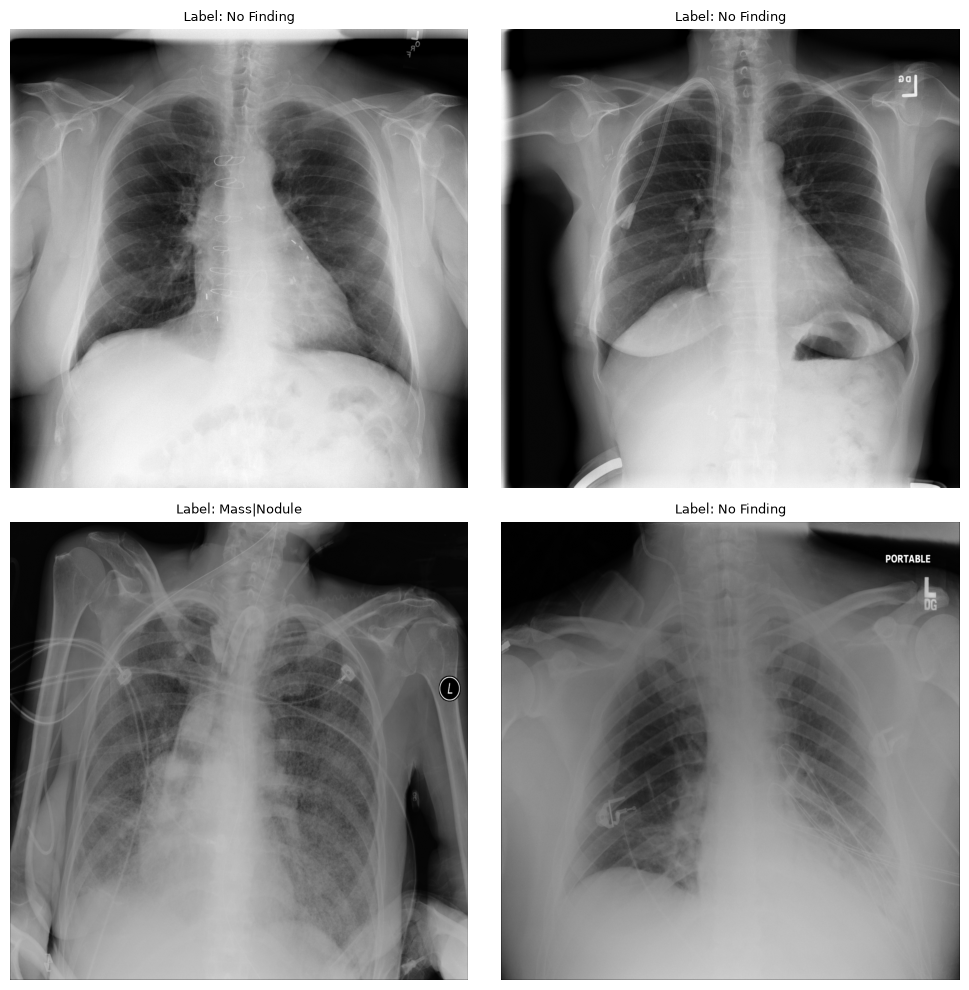

In [8]:
import random
from PIL import Image

# Select 4 random image records
sample_df = df.sample(4, random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    image_path = IMAGE_DIR / row["Image Index"]

    img = Image.open(image_path).convert("L")

    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {row['Finding Labels']}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
import numpy as np
image_path = IMAGE_DIR / df.iloc[0]["Image Index"]

img = Image.open(image_path).convert("L")


img_array = np.array(img)

print("Image dimensions:", img.size)
print("Image shape:", img_array.shape)
print("Data type:", img_array.dtype)
print("Minimum pixel value:", img_array.min())
print("Maximum pixel value:", img_array.max())

Image dimensions: (1024, 1024)
Image shape: (1024, 1024)
Data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


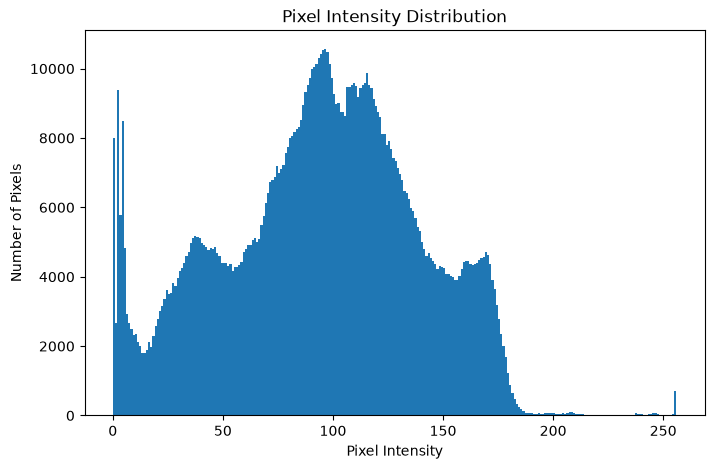

In [11]:
plt.figure(figsize=(8, 5))

plt.hist(img_array.ravel(), bins=256, range=(0, 256))

plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")

plt.show()

In [ ]:
The histogram shows that most pixel values are between 70 and 175,while fewer pixels are present near 0 and 255. 
This helps us understand the brightness and intensity distribution of the X-ray image before preprocessing.